# HW4 – Frequent Itemsets and Association Rules

In [1]:
from itertools import combinations

transactions = [
    ["Bread", "Butter", "Milk"],
    ["Bread", "Butter", "Eggs"],
    ["Milk", "Cereal"],
    ["Bread", "Eggs"],
    ["Milk", "Cereal", "Yogurt"],
    ["Diapers", "Beer"],
    ["Diapers", "Beer", "Chips"],
    ["Apples", "Bananas"],
    ["Apples", "Bananas", "Milk"],
    ["Bread", "Butter", "Milk", "Eggs"],
    ["Cereal", "Milk"],
    ["Bread", "Butter", "Milk", "Eggs"],
    ["Apples", "Milk"],
    ["Diapers", "Beer", "Bread", "Eggs"],
    ["Yogurt", "Cereal"],
    ["Bread", "Butter", "Bananas", "Milk"],
    ["Milk", "Eggs"],
    ["Apples", "Bananas", "Yogurt"],
    ["Bread", "Butter", "Cereal", "Milk"],
    ["Chips", "Salsa"],
]

## Part 1: Frequent itemsets

### Support, confidence, lift

In [2]:
def support(itemset, transactions):
    """Fraction of transactions that contain every item of `itemset`."""
    items = set(itemset)
    return sum(items <= set(t) for t in transactions) / len(transactions)


def confidence(antecedent, consequent, transactions):
    """conf(A -> C) = sup(A u C) / sup(A)."""
    return support(set(antecedent) | set(consequent), transactions) / support(antecedent, transactions)


def lift(antecedent, consequent, transactions):
    """lift(A -> C) = conf(A -> C) / sup(C)."""
    return confidence(antecedent, consequent, transactions) / support(consequent, transactions)

### Apriori

Itemsets are sorted tuples, so two (k-1)-itemsets can be joined exactly when they agree on their first k-2 items.

In [3]:
def join(prev):
    """Join sorted (k-1)-tuples sharing their first k-2 items into k-tuples."""
    prev = sorted(prev)
    return [a + (b[-1],) for i, a in enumerate(prev) for b in prev[i + 1:] if a[:-1] == b[:-1]]


def prune(candidates, prev):
    """Split candidates into (kept, pruned); pruned if some (k-1)-subset is not in `prev`."""
    prev = set(prev)
    kept, pruned = [], []
    for c in candidates:
        ok = all(sub in prev for sub in combinations(c, len(c) - 1))
        (kept if ok else pruned).append(c)
    return kept, pruned


def apriori(transactions, min_sup):
    """Return ({itemset: support} for all frequent itemsets, {k: pruned k-candidates})."""
    items = sorted({i for t in transactions for i in t})
    frequent, pruned_by_k = {}, {}
    level = [(i,) for i in items if support((i,), transactions) >= min_sup]
    frequent.update({c: support(c, transactions) for c in level})
    k = 2
    while level:
        kept, pruned_by_k[k] = prune(join(level), level)       # join, then prune
        counted = {c: support(c, transactions) for c in kept}  # count
        level = [c for c, s in counted.items() if s >= min_sup]
        frequent.update({c: counted[c] for c in level})
        k += 1
    return frequent, pruned_by_k

### Results for `min_sup = 0.25`

In [4]:
min_sup = 0.25
freq, pruned_by_k = apriori(transactions, min_sup)

for k in range(1, max(map(len, freq)) + 2):
    print(f"k={k}")
    for itemset, s in sorted(freq.items(), key=lambda x: (-x[1], x[0])):
        if len(itemset) == k:
            print(f"    {itemset}  support={s:.2f}")
    if k > 1:
        print(f"    pruned candidates: {len(pruned_by_k[k])} {pruned_by_k[k]}")

k=1
    ('Milk',)  support=0.55
    ('Bread',)  support=0.40
    ('Butter',)  support=0.30
    ('Eggs',)  support=0.30
    ('Cereal',)  support=0.25
k=2
    ('Bread', 'Butter')  support=0.30
    ('Bread', 'Eggs')  support=0.25
    ('Bread', 'Milk')  support=0.25
    ('Butter', 'Milk')  support=0.25
    pruned candidates: 0 []
k=3
    ('Bread', 'Butter', 'Milk')  support=0.25
    pruned candidates: 2 [('Bread', 'Butter', 'Eggs'), ('Bread', 'Eggs', 'Milk')]
k=4
    pruned candidates: 0 []


### Itemset {Butter, Bread, Eggs}

In [5]:
target = ("Bread", "Butter", "Eggs")
for k in (1, 2):
    for sub in combinations(target, k):
        print(f"{sub}: support={support(sub, transactions):.2f}")
print("pruned at k=3:", target in pruned_by_k[3])

('Bread',): support=0.40
('Butter',): support=0.30
('Eggs',): support=0.30
('Bread', 'Butter'): support=0.30
('Bread', 'Eggs'): support=0.25
('Butter', 'Eggs'): support=0.15
pruned at k=3: True


## Part 2: Association rules

For a frequent itemset F, the rule `(F - C) -> C` has confidence `sup(F) / sup(F - C)`. Moving an item from the antecedent to the consequent can only lower confidence, so if a rule with consequent C fails `min_conf`, so does every rule whose consequent is a superset of C.

`apriori_rules` therefore runs Apriori over *consequents*: start with 1-item consequents, **join** the high-confidence ones, **prune** candidates that have a low-confidence sub-consequent, **count** (compute confidence) the rest, and repeat.

In [6]:
def apriori_rules(itemset, transactions, min_conf):
    """All rules A -> C with A u C = itemset and confidence >= min_conf."""
    rules = []

    def count(consequents):
        good = []
        for C in consequents:
            A = tuple(i for i in itemset if i not in C)
            conf = confidence(A, C, transactions)
            if conf >= min_conf:
                good.append(C)
                rules.append((A, C, conf, lift(A, C, transactions)))
        return good

    good = count([(i,) for i in itemset])
    m = 1
    while good and m + 1 < len(itemset):        # antecedent must stay non-empty
        kept, _ = prune(join(good), good)
        good = count(kept)
        m += 1
    return rules

In [7]:
min_conf = 0.6
rules = [r for itemset in freq if len(itemset) >= 2
         for r in apriori_rules(itemset, transactions, min_conf)]

print(f"{len(rules)} rules (min_sup={min_sup}, min_conf={min_conf})\n")
print(f"{'rule':<36}{'support':>8}{'conf':>8}{'lift':>8}")
for A, C, conf, l in sorted(rules, key=lambda r: (-r[2], -r[3])):
    rule = f"{set(A)} -> {set(C)}"
    print(f"{rule:<36}{support(set(A) | set(C), transactions):>8.2f}{conf:>8.2f}{l:>8.2f}")

11 rules (min_sup=0.25, min_conf=0.6)

rule                                 support    conf    lift
{'Bread', 'Milk'} -> {'Butter'}         0.25    1.00    3.33
{'Butter'} -> {'Bread'}                 0.30    1.00    2.50
{'Milk', 'Butter'} -> {'Bread'}         0.25    1.00    2.50
{'Butter'} -> {'Bread', 'Milk'}         0.25    0.83    3.33
{'Eggs'} -> {'Bread'}                   0.25    0.83    2.08
{'Butter'} -> {'Milk'}                  0.25    0.83    1.52
{'Bread', 'Butter'} -> {'Milk'}         0.25    0.83    1.52
{'Bread'} -> {'Butter'}                 0.30    0.75    2.50
{'Bread'} -> {'Milk', 'Butter'}         0.25    0.62    2.50
{'Bread'} -> {'Eggs'}                   0.25    0.62    2.08
{'Bread'} -> {'Milk'}                   0.25    0.62    1.14


## Part 3: Hierarchical agglomerative clustering

Each step merges the two nearest clusters. The cluster distance is a parameter: `min_dist` and `max_dist` are the functions that combine the distances `d(a,k)` and `d(b,k)` into the distance from the merged cluster `a u b` to another cluster `k`. For single linkage (min) and complete linkage (max) this gives the new row exactly, so distances are updated incrementally and never recomputed from the points. The merge history is stored in SciPy's linkage format `[cluster_i, cluster_j, distance, size]` (new cluster `n+t` is created at merge `t`), which gives the dendrogram and the cluster memberships for any number of clusters.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from scipy.spatial.distance import cdist

points = np.loadtxt("clustering.txt", delimiter=",")

min_dist = np.minimum   # d(a u b, k) = min(d(a,k), d(b,k))
max_dist = np.maximum   # d(a u b, k) = max(d(a,k), d(b,k))


def hac(points, cluster_dist):
    """Agglomerative clustering. Returns the merge history Z (n-1 rows: id1, id2, dist, size)."""
    n = len(points)
    D = cdist(points, points)                 # the only from-scratch distance computation
    np.fill_diagonal(D, np.inf)
    ids = list(range(n))                      # cluster id stored in each row/column
    size = [1] * n
    active = np.ones(n, dtype=bool)
    Z = []
    for step in range(n - 1):
        masked = np.where(active[:, None] & active[None, :], D, np.inf)
        a, b = np.unravel_index(np.argmin(masked), D.shape)
        Z.append([ids[a], ids[b], D[a, b], size[a] + size[b]])
        # incremental update: merged cluster reuses row/column a, b is deactivated
        D[a, :] = D[:, a] = cluster_dist(D[a, :], D[b, :])
        D[a, a] = np.inf
        active[b] = False
        ids[a], size[a] = n + step, size[a] + size[b]
    return np.array(Z)


def cut(Z, k):
    """Cluster label (0..k-1) of every point after merging down to k clusters."""
    n = len(Z) + 1
    parent = list(range(2 * n - 1))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for t, (i, j, _, _) in enumerate(Z[:n - k]):
        parent[find(int(i))] = parent[find(int(j))] = n + t
    roots = [find(p) for p in range(n)]
    return np.unique(roots, return_inverse=True)[1]

### Dataset

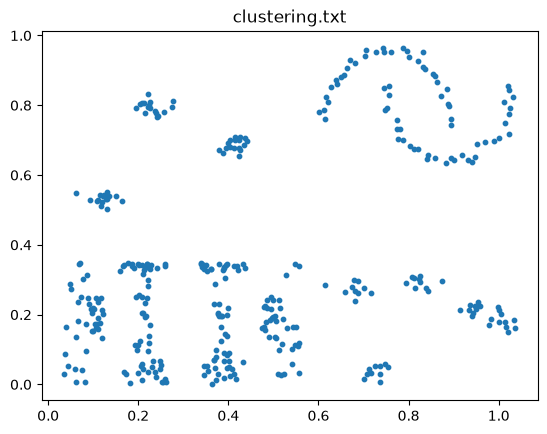

In [9]:
plt.scatter(*points.T, s=10)
plt.title("clustering.txt")
plt.show()

### Results for 13 clusters

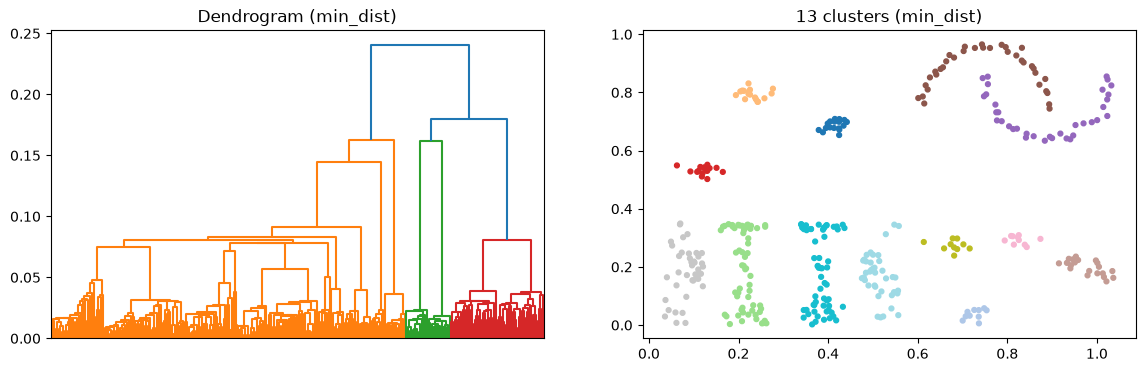

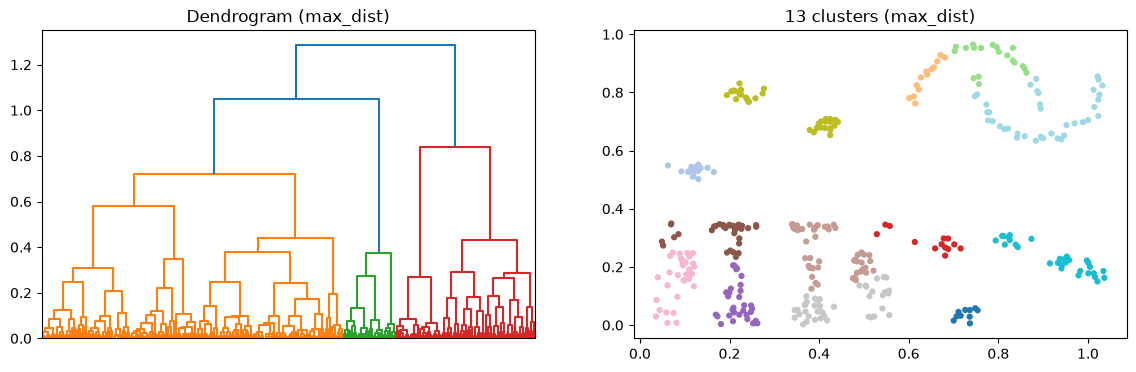

In [10]:
for name, f in [("min_dist", min_dist), ("max_dist", max_dist)]:
    Z = hac(points, f)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    dendrogram(Z, ax=ax1, no_labels=True)
    ax1.set_title(f"Dendrogram ({name})")
    ax2.scatter(*points.T, c=cut(Z, 13), cmap="tab20", s=12)
    ax2.set_title(f"13 clusters ({name})")
    plt.show()